# Element-Specific XMCD and Faraday Rotation of GdFeCo

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/dschick/udkm1Dsim/blob/develop/examples/07-xray_reflectivity/04-XMCD_GdFeCo.ipynb)

In this example the element-specific X-ray magnetic circular dichroism (XMCD) of soft X-rays is calculated for the all-optical switching of the GdFeCo ferrimagnet of the [eLLB example](#example_eLLB), together with the static Faraday rotation.
The magnetization dynamics of both sublattices are not recalculated, but loaded from the result, which was saved there.
In order to probe the Fe and the Gd sublattice separately, the gyrotropic part of the dielectric tensor of the GdFeCo layer is given by one dispersion per sublattice, see the [magnetic sublattices in the dielectric example](#dielectric_sublattices).
The simulation mimics the time-resolved XMCD experiment of {cite:t}`radu2011`, who found that the Fe sublattice reverses within about 300 fs and the Gd sublattice only within about 1.5 ps, so that both are transiently aligned in parallel - the transient ferromagnetic-like state.

:::{admonition} References {cite}`radu2011,raposo2022`
:class: seealso
I. Radu et al.,
*Transient ferromagnetic-like state mediating ultrafast reversal of antiferromagnetically coupled spins*,
[Nature 472, 205 (2011)](https://doi.org/10.1038/nature09901)

V. Raposo, F. García-Sánchez, U. Atxitia, and E. Martínez,
*Realistic micromagnetic description of all-optical ultrafast switching processes in ferrimagnetic alloys*,
[Phys. Rev. B 105, 104432 (2022)](https://doi.org/10.1103/PhysRevB.105.104432)
:::

## Setup

Do all necessary imports and settings.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

try:
    import udkm1Dsim as ud
except ImportError:
    %pip install udkm1Dsim
    import udkm1Dsim as ud

u = ud.u  # import the pint unit registry from udkm1Dsim
u.setup_matplotlib()  # use matplotlib with pint units

%matplotlib inline

try:
    plt.style.use(["mbistyles.base", "mbistyles.paper"])  # matplotlib styles of the MBI
except OSError:
    pass  # mbistyles is not installed, the default matplotlib style is used

## Atomic and Magnetic Form Factors

:::{admonition} Reference {cite}`prieto2003`
:class: seealso
J. E. Prieto, F. Heigl, O. Krupin, G. Kaindl, and K. Starke,
*Magneto-optics of Gd and Tb in the soft x-ray resonance regions*,
[Phys. Rev. B 68, 134453 (2003)](https://doi.org/10.1103/PhysRevB.68.134453)
:::

The atomic and magnetic form factors of Gd at its $M_{5,4}$ edges from 1160 eV to 1230 eV are converted from the magneto-optical constants of {cite:t}`prieto2003`, which were measured on a Gd film at 30 K, and are read from local files.
Outside of this range, the files contain the tabulated atomic form factors of {cite:t}`chantler2003` and zero magnetic form factors, which is sufficient at the Fe $L_{3,2}$ edges.

For Fe, the atomic form factors of the [resonant magnetic X-ray example](#example_resonant_magnetic_xray) and the tabulated magnetic form factors of **udkm1Dsim** are used.
Here, the transition-metal sublattice FeCo is approximated by Fe.

In [2]:
Fe = ud.Atom("Fe", atomic_form_factor_path="./Fe.cf")
Gd = ud.Atom("Gd", atomic_form_factor_path="./Gd_M45.cf", magnetic_form_factor_path="./Gd_M45.mf")
Si = ud.Atom("Si")
N = ud.Atom("N")

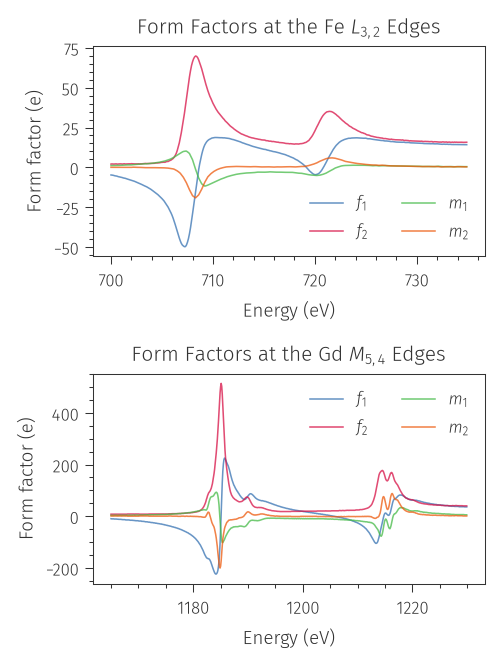

In [3]:
energies_Fe = np.r_[700:735:0.1] * u.eV
energies_Gd = np.r_[1165:1230:0.1] * u.eV

plt.figure(figsize=[3.4, 4.5])
for i, (atom, energies, edge) in enumerate(
    ((Fe, energies_Fe, "Fe $L_{3,2}$"), (Gd, energies_Gd, "Gd $M_{5,4}$"))
):
    f = atom.get_atomic_form_factor(energies)
    m = atom.get_magnetic_form_factor(energies)
    plt.subplot(2, 1, i + 1)
    # f = f_1 - i f_2 and m = m_1 - i m_2
    plt.plot(energies, f.real, label="$f_1$")
    plt.plot(energies, -f.imag, label="$f_2$")
    plt.plot(energies, m.real, label="$m_1$")
    plt.plot(energies, -m.imag, label="$m_2$")
    plt.xlabel("Energy (eV)")
    plt.ylabel("Form factor (e)")
    plt.legend(ncol=2)
    plt.title(f"Form Factors at the {edge} Edges")
plt.tight_layout()
plt.show()

The magnetic form factor $m_2$, which gives the XMCD, is negative at the Fe $L_3$ and at the Gd $M_5$ edge.
Hence, the antiparallel Fe and Gd sublattices of the ferrimagnet give an XMCD of opposite sign at both edges.

## Structure

The sublattice magnetization map of the eLLB example for the fluence above the switching threshold is loaded by {py:meth}`Result.load() <udkm1Dsim.simulations.result.Result.load>`, see the [simulations and results example](#example_simulations_and_results).
Its metadata hold the sample structure as YAML, from which the 10 nm thick GdFeCo film on a 100 nm thick Si$_3$N$_4$ membrane is restored with all its parameters by {py:meth}`Structure.from_yaml() <udkm1Dsim.structures.structure.Structure.from_yaml>`.

In the eLLB example, only the refractive indices at the wavelength of the pump of 800 nm are given.
Here, the dielectrics of the layers in the soft X-ray range are given by {py:meth}`Dielectric.from_atoms() <udkm1Dsim.structures.dielectric.Dielectric.from_atoms>` with the refractive indices as fallback.
The `sublattices` assign the Fe atoms to the transition-metal sublattice 0 and the Gd atoms to the rare-earth sublattice 1 of the magnetic parameters of the layer, so that the gyrotropic dispersion of every sublattice follows from the magnetic form factors of its atoms.

In [4]:
res_sublattices = ud.Result.load("../04-magnetization/GdFeCo_sublattice_magnetization.h5")

S = ud.Structure.from_yaml(res_sublattices.attrs["structure"])
layer_ids, layers = S.unique_layers
layer_GdFeCo = layers[layer_ids.index("GdFeCo")]
layer_Si3N4 = layers[layer_ids.index("Si3N4")]

# one gyrotropic dispersion per sublattice: Fe for the TM and Gd for the RE sublattice
layer_GdFeCo.optical.dielectric = ud.Dielectric.from_atoms(
    [(Fe, 0.75), (Gd, 0.25)],
    sublattices=[0, 1],
    fallback=ud.Dispersion.from_ref_index(3.0 + 3.5j),
)
layer_Si3N4.optical.dielectric = ud.Dielectric.from_atoms(
    [(Si, 3), (N, 4)], fallback=ud.Dispersion.from_ref_index(2.0 + 0j)
)
select = S.positions_per_unique_layer["GdFeCo"]

S

times,sub-structure,thickness
10,GdFeCo,10 nm
20,Si3N4,100 nm


The dielectric of the GdFeCo layer couples the gyrotropic dispersion of every sublattice to its own magnetization, as its `gyrotropy` is `"sublattices"`:

In [5]:
layer_GdFeCo.optical

Optical Parameters
╔═════════════╦══════════╦═══════════════════════════════════════════════════════════════════════════╦════════╗
║ Parameter   ║  Symbol  ║                                                                     Value ║ Unit   ║
╠═════════════╬══════════╬═══════════════════════════════════════════════════════════════════════════╬════════╣
║ dielectric  ║    ε⁰    ║ atomic form factors of 3×Fe, Gd from 12.93 eV to 30.01 keV | n = 3 + 3.5i ║        ║
║             ║   εᵐ₁    ║             magnetic form factors of Fe in 3×Fe, Gd from 31 eV to 100 keV ║        ║
║             ║   εᵐ₂    ║              magnetic form factors of Gd in 3×Fe, Gd from 0 eV to 100 keV ║        ║
║             ║    m     ║                 magnetization of every sublattice (gyrotropy sublattices) ║        ║
║             ║   s(η)   ║                                                     1/(1+η) for ε⁰ and εᵐ ║        ║
╚═════════════╩══════════╩═══════════════════════════════════════════════════════════════════════════╩════════╝

## Sublattice Dynamics

The out-of-plane magnetizations of both sublattices of the loaded result are averaged over the film.
The transient ferromagnetic-like state, in which both sublattices point along $-z$, is shaded.

ferromagnetic-like state: 0.54 - 0.90 ps


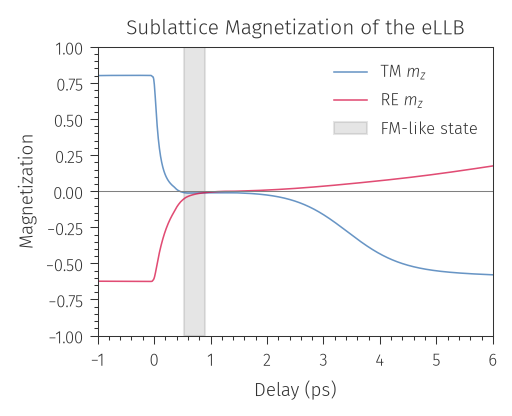

In [6]:
delays = res_sublattices.quantity("delays", "ps")
# cartesian magnetization of both sublattices averaged over the film
m = np.mean(res_sublattices.sublattice_magnetization_map[:, select], axis=1)
same = np.flatnonzero((m[:, 0, 2] < -0.01) & (m[:, 1, 2] < -0.01))
window = delays[same[[0, -1]]].magnitude
print("ferromagnetic-like state: {:.2f} - {:.2f} ps".format(*window))

plt.figure()
plt.plot(delays, m[:, 0, 2], label="TM $m_z$")
plt.plot(delays, m[:, 1, 2], label="RE $m_z$")
plt.axvspan(*window, color="gray", alpha=0.2, label="FM-like state")
plt.axhline(0, color="gray", lw=0.5)
plt.xlim(-1, 6)
plt.ylim(-1, 1)
plt.xlabel("Delay (ps)")
plt.ylabel("Magnetization")
plt.legend(loc="upper right")
plt.title("Sublattice Magnetization of the eLLB")
plt.show()

## Static XMCD Spectra

The {py:class}`Elzo <udkm1Dsim.simulations.scattering.elzo.Elzo>` simulation is set up as in the [resonant magnetic X-ray example](#example_resonant_magnetic_xray), see the [scattering overview](#example_scattering_overview) for its experiment parameters and polarizations.
The X-rays are transmitted through the film and the membrane under normal incidence, i.e. for $\theta = 90°$, along the out-of-plane magnetization.
The XMCD of the circularly polarized X-rays is given by the transmissivity $T$ and the transmissivity $T_\phi$ for the opposite magnetization:

$$
\mathrm{XMCD} = \frac{T - T_\phi}{T + T_\phi}
$$

The static spectra are calculated for the magnetizations of the layer, i.e. for fully saturated sublattices.
The `gyrotropy` of the dielectric switches between the gyrotropic dispersion of every sublattice coupled to its own magnetization, `"sublattices"`, and the sum of the dispersions coupled to the net magnetization weighted by the saturation magnetizations, `"net"`.

In [7]:
dyn_mag = ud.Elzo(S, True)
dyn_mag.disp_messages = True
dyn_mag.save_data = False

dyn_mag.energy = energies_Fe
dyn_mag.theta = np.r_[90] * u.deg  # normal incidence

dyn_mag

parameter,value
force recalc,True
cache directory,./
display messages,True
save data,False
progress bar,True
energy,700 eV .. 734.9 eV
wavelength,1.687 nm .. 1.771 nm
wavenumber,3.547 1/nm .. 3.724 1/nm
theta,90 deg .. 90 deg
q_z,7.095 1/nm .. 7.449 1/nm


incoming polarizations set to: circ +
analyzer polarizations set to: unpolarized
Calculating _homogeneous_reflectivity_transmissivity_ ...
Elapsed time for _homogeneous_reflectivity_transmissivity_: 0.008589 s
Calculating _homogeneous_reflectivity_transmissivity_ ...
Elapsed time for _homogeneous_reflectivity_transmissivity_: 0.012527 s
Calculating _homogeneous_reflectivity_transmissivity_ ...
Elapsed time for _homogeneous_reflectivity_transmissivity_: 0.008219 s
Calculating _homogeneous_reflectivity_transmissivity_ ...
Elapsed time for _homogeneous_reflectivity_transmissivity_: 0.016614 s


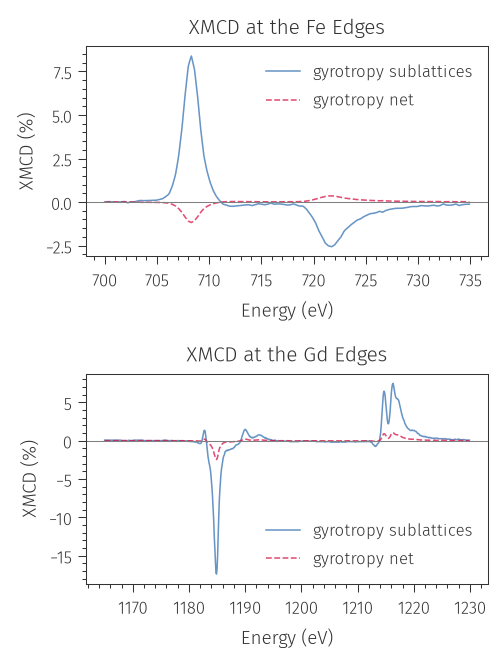

In [8]:
gyrotropies = ["sublattices", "net"]
edges = {"Fe": energies_Fe, "Gd": energies_Gd}

xmcd = {}
dyn_mag.set_polarization("circ +", "none")
for gyrotropy in gyrotropies:
    layer_GdFeCo.optical.dielectric.gyrotropy = gyrotropy
    for edge, energies in edges.items():
        dyn_mag.energy = energies
        res = dyn_mag.homogeneous_reflectivity_transmissivity()
        xmcd[gyrotropy, edge] = ((res.T - res.T_phi) / (res.T + res.T_phi))[:, 0]

plt.figure(figsize=[3.4, 4.5])
for i, (edge, energies) in enumerate(edges.items()):
    plt.subplot(2, 1, i + 1)
    for gyrotropy, style in zip(gyrotropies, ["-", "--"]):
        plt.plot(energies, 100 * xmcd[gyrotropy, edge], style, label=f"gyrotropy {gyrotropy}")
    plt.axhline(0, color="gray", lw=0.5)
    plt.xlabel("Energy (eV)")
    plt.ylabel("XMCD (%)")
    plt.legend()
    plt.title(f"XMCD at the {edge} Edges")
plt.tight_layout()
plt.show()

For the gyrotropy `"sublattices"` the XMCD is element specific: it is positive at the Fe $L_3$ edge for the Fe sublattice along $+z$ and negative at the Gd $M_5$ edge for the Gd sublattice along $-z$.
For the gyrotropy `"net"` both edges probe the same net magnetization, which is small and negative, since the Gd sublattice slightly dominates.
In order to simulate element-specific experiments on ferrimagnets, the gyrotropy `"sublattices"` is required.

The energies of the largest XMCD at both edges are used for the time-resolved simulations below:

In [9]:
energies_xmcd = [
    edges[edge][np.argmax(np.abs(xmcd["sublattices", edge]))].m_as("eV") for edge in edges
] * u.eV
energies_xmcd

Magnitude,[708.3000000000019 1184.899999999982]
Units,eV


## Static Faraday Rotation

For linearly $\sigma$-polarized X-rays, the polarization of the transmitted light is rotated by the out-of-plane magnetization and becomes elliptical - the Faraday effect.
The rotation and the ellipticity, i.e. the angle $\epsilon$ of the polarization ellipse with $\tan\epsilon$ being the ratio of its minor and major axis, follow from the Jones matrix of the transmission by {py:meth}`homogeneous_rotation_ellipticity <udkm1Dsim.simulations.scattering.multilayer.MultilayerScattering.homogeneous_rotation_ellipticity>`.

incoming polarizations set to: sigma
analyzer polarizations set to: unpolarized
Calculating _homogeneous_rotation_ellipticity_ ...
Elapsed time for _homogeneous_rotation_ellipticity_: 0.007254 s
Calculating _homogeneous_rotation_ellipticity_ ...
Elapsed time for _homogeneous_rotation_ellipticity_: 0.009134 s


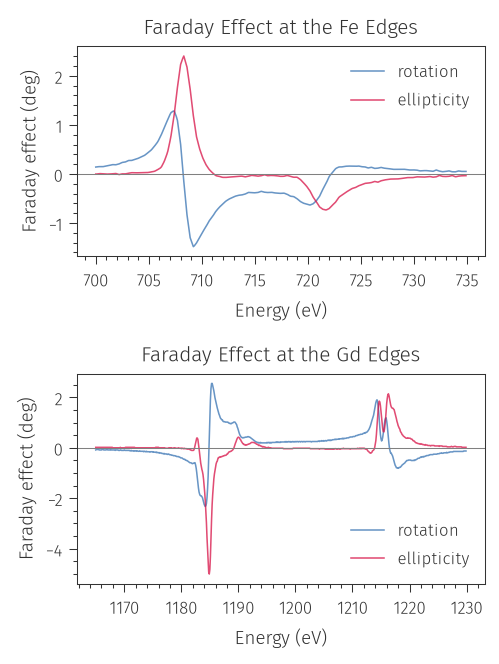

In [10]:
layer_GdFeCo.optical.dielectric.gyrotropy = "sublattices"
dyn_mag.set_polarization("sigma", "none")

plt.figure(figsize=[3.4, 4.5])
for i, (edge, energies) in enumerate(edges.items()):
    dyn_mag.energy = energies
    res_faraday = dyn_mag.homogeneous_rotation_ellipticity()
    plt.subplot(2, 1, i + 1)
    plt.plot(energies, res_faraday.rot_T[:, 0], label="rotation")
    plt.plot(energies, res_faraday.ell_T[:, 0], label="ellipticity")
    plt.axhline(0, color="gray", lw=0.5)
    plt.xlabel("Energy (eV)")
    plt.ylabel("Faraday effect (deg)")
    plt.legend()
    plt.title(f"Faraday Effect at the {edge} Edges")
plt.tight_layout()
plt.show()

The ellipticity follows the absorptive part $m_2$ of the magnetic form factors, i.e. the XMCD, while the rotation follows their dispersive part $m_1$, which is largest slightly beside the absorption maxima.
Both reach a few degrees for the 10 nm thick film.

## Time-Resolved XMCD

The {py:meth}`inhomogeneous_reflectivity_transmissivity <udkm1Dsim.simulations.scattering.multilayer.MultilayerScattering.inhomogeneous_reflectivity_transmissivity>` method takes the loaded result as `magnetization_map`, i.e. its `sublattice_magnetization_map` $M \times N \times P \times 3$ with the $P = 2$ sublattices, and its `delays`.
The transient XMCD is calculated at the energies of the largest static XMCD for the gyrotropy `"sublattices"`.

In [11]:
dyn_mag.energy = energies_xmcd
dyn_mag.set_polarization("circ +", "none")

layer_GdFeCo.optical.dielectric.gyrotropy = "sublattices"

try:
    from dask.distributed import Client

    client = Client(threads_per_worker=1)  # one worker per CPU core
    res = dyn_mag.inhomogeneous_reflectivity_transmissivity(
        magnetization_map=res_sublattices, calc_type="parallel", dask_client=client
    )
    client.close()
except ImportError:
    res = dyn_mag.inhomogeneous_reflectivity_transmissivity(
        magnetization_map=res_sublattices,
    )

xmcd_transient = ((res.T - res.T_phi) / (res.T + res.T_phi))[:, :, 0]

incoming polarizations set to: circ +
analyzer polarizations set to: unpolarized
Calculating _inhomogeneous_reflectivity_transmissivity_Elzo_ ...


Progress:   0%|          | 0/2600 [00:00<?, ?it/s]

Elapsed time for _inhomogeneous_reflectivity_transmissivity_Elzo_: 13.039949 s


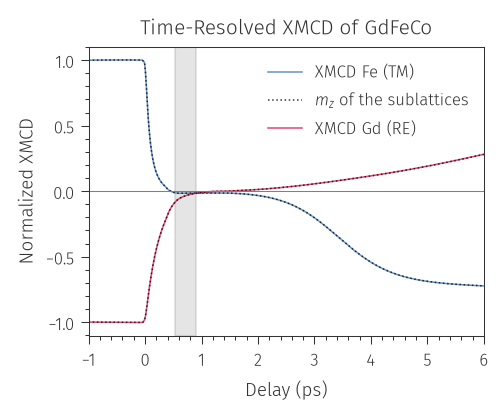

In [12]:
before = delays < 0 * u.ps
labels = ["Fe (TM)", "Gd (RE)"]

plt.figure()
for i, label in enumerate(labels):
    # normalized to the magnitude before the excitation, keeping the sign
    signal = xmcd_transient[:, i]
    plt.plot(
        delays,
        signal / np.abs(np.mean(signal[before])),
        color=f"C{i}",
        label=f"XMCD {label}",
    )
    plt.plot(
        delays,
        m[:, i, 2] / np.abs(np.mean(m[before, i, 2])),
        ":",
        color="k",
        label="$m_z$ of the sublattices" if i == 0 else None,
    )
plt.axvspan(*window, color="gray", alpha=0.2)
plt.axhline(0, color="gray", lw=0.5)
plt.xlim(-1, 6)
plt.xlabel("Delay (ps)")
plt.ylabel("Normalized XMCD")
plt.legend(loc="upper right")
plt.title("Time-Resolved XMCD of GdFeCo")

plt.show()

For the gyrotropy `"sublattices"`, the normalized XMCD of each edge coincides with the normalized magnetization of its sublattice, so that the XMCD is linear in the magnetization for this film.
The Fe XMCD changes its sign first, the Gd XMCD follows later, and in between both sublattices are aligned in parallel, as in the experiment of {cite:t}`radu2011`.
In this simulation, however, both sublattices are quenched almost completely in the ferromagnetic-like state, see the discussion of the heat model in the [eLLB example](#example_eLLB).